In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path(r"c:\Users\joube\OneDrive - Monash University\Year 5 - Semester 2\MMA3001\MMA3001-Project")

# ---------------------------------------------------------------------
# Section 1: Environmental sensor dataset
# Purpose:
#   This file contains the environmental telemetry records captured by the
#   building sensors. Each row represents a sensor reading event and the
#   JSON payload contains the measured variables (temperature, humidity,
#   pressure, CO2, battery, etc.).
#
# Why the columns are selected explicitly:
#   - We keep the primary identifiers and timestamps required for traceability
#   - We retain the raw measurement payload in jsondata for later parsing
#   - We exclude unrelated fields that are not needed for the initial analysis
# ---------------------------------------------------------------------
env_file = project_dir / "5EnvSensor_MayToDec2024_180kRows.csv"
env_df = pd.read_csv(env_file)
env_columns = [
    "id",
    "sensorid",
    "devicetype",
    "jsondata",
    "status",
    "processing_errors",
    "createdate",
    "processdate",
]
env_split = env_df[env_columns].copy()

# ---------------------------------------------------------------------
# Section 2: Occupancy sensor dataset
# Purpose:
#   This file captures room or floor occupancy status events from the
#   occupancy sensors. Each row contains the device identifier, room/floor
#   reference, occupancy state, headcount, and the timestamps of when the
#   state was recorded and changed.
#
# Why the columns are selected explicitly:
#   - We need the device and space IDs to correlate occupancy with location
#   - We keep the current and previous occupancy state to understand transitions
#   - We retain headcount and timestamps for trend and event analysis
# ---------------------------------------------------------------------
occ_file = project_dir / "5occupancySensor_MayToDec2024_9MRows.csv"
occ_df = pd.read_csv(occ_file)
occ_columns = [
    "id",
    "deviceid",
    "floorspaceid",
    "occupancystatus",
    "headcount",
    "collecteddate",
    "occupancystatuschangedate",
    "previousoccupancystatus",
]
occ_split = occ_df[occ_columns].copy()

# ---------------------------------------------------------------------
# Section 3: Sensor ID and location mapping dataset
# Purpose:
#   This file provides the mapping between sensor identifiers and physical
#   building locations. It is used to connect the sensor readings to the
#   actual building, floor, room, and area metadata.
#
# Why the columns are selected explicitly:
#   - The mapping is required to align sensor IDs with physical labels
#   - Building and floor/room fields support spatial joins for analysis
#   - The metadata provides a reference for later merge operations with the
#     environmental and occupancy datasets
# ---------------------------------------------------------------------
loc_file = project_dir / "Sensor ID and Locations - ENV.csv"
loc_df = pd.read_csv(loc_file)
loc_columns = [
    "Building",
    "Floor/Room",
    "Area",
    "Physical Label",
    "Sensor",
    "ID",
]
loc_split = loc_df[loc_columns].copy()

# ---------------------------------------------------------------------
# Quick validation section
# Purpose:
#   Provide a lightweight sanity check to confirm that each section loaded
#   successfully and that the expected columns are present before further
#   engineering or analysis work proceeds.
# ---------------------------------------------------------------------
print("ENV columns:")
print(env_split.head())
print("\nOCCUPANCY columns:")
print(occ_split.head())
print("\nLOCATION columns:")
print(loc_split.head())


ENV columns:
   id      sensorid devicetype  \
0   2  6.012000e+12        env   
1   4  6.012000e+12        env   
2   5  6.012000e+12        env   
3  16  6.012000e+12        env   
4  24  6.012000e+12        env   

                                            jsondata     status  \
0  [{"values": [{"time": 1702273965, "value": 4.1...  Processed   
1  [{"values": [{"time": 1702273965, "value": 4.1...  Processed   
2  [{"values": [{"time": 1702270857, "value": 4.1...  Processed   
3  [{"values": [{"time": 1683326565, "value": 4.1...  Processed   
4  [{"values": [{"time": 1709186696, "value": 4.1...  Processed   

   processing_errors                     createdate  \
0                NaN  2024-02-29 03:11:58.210358+11   
1                NaN  2024-02-29 17:09:08.833822+11   
2                NaN  2024-02-29 17:09:12.444245+11   
3                NaN  2024-02-29 17:10:24.443407+11   
4                NaN  2024-02-29 17:11:11.348578+11   

                     processdate  
0  2024-02-29

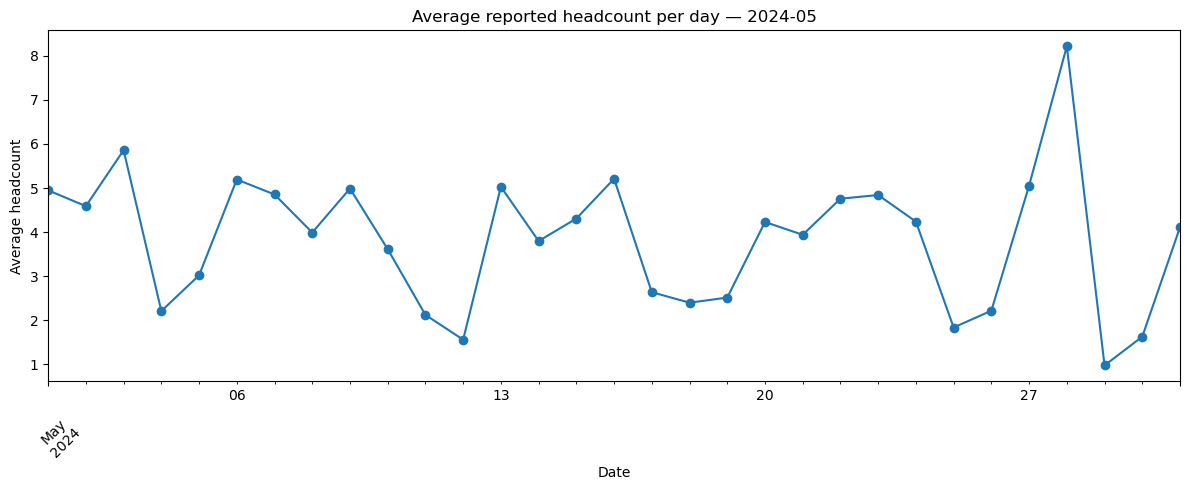

In [2]:
# Set the month you want to visualise
MONTH = "2024-05"
target_month = pd.Period(MONTH, freq="M")

occ_plot = occ_split.copy()

# Normalize timestamps to one datetime type, including mixed timezone values
occ_plot["collecteddate"] = pd.to_datetime(
    occ_plot["collecteddate"],
    errors="coerce",
    utc=True,
).dt.tz_localize(None)

occ_plot["headcount"] = pd.to_numeric(
    occ_plot["headcount"],
    errors="coerce",
)

# Drop rows where either value could not be parsed
occ_plot = occ_plot.dropna(subset=["collecteddate", "headcount"])

# Keep only records from the selected month
occ_plot = occ_plot[
    occ_plot["collecteddate"].dt.to_period("M") == target_month
]

if occ_plot.empty:
    print(f"No occupancy records found for {MONTH}.")
else:
    daily_headcount = (
        occ_plot.groupby(occ_plot["collecteddate"].dt.floor("D"))["headcount"]
        .mean()
    )

    ax = daily_headcount.plot(
        kind="line",
        marker="o",
        figsize=(12, 5),
    )
    ax.set(
        title=f"Average reported headcount per day — {MONTH}",
        xlabel="Date",
        ylabel="Average headcount",
    )
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [3]:
import json
import pandas as pd

env_readable = env_split.copy()

# Parse timestamps consistently; invalid values become NaT
for column in ["createdate", "processdate"]:
    env_readable[column] = pd.to_datetime(
        env_readable[column],
        errors="coerce",
        utc=True,
    )

# Convert JSON strings into dictionaries
def parse_json_payload(value):
    if pd.isna(value):
        return {}

    try:
        parsed = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        return {}

    # Sensor payloads are expected to be JSON objects
    return parsed if isinstance(parsed, dict) else {"value": parsed}

payloads = env_readable["jsondata"].map(parse_json_payload)

# Turn JSON keys into normal columns, prefixed to keep names distinct
measurements = pd.json_normalize(payloads.tolist(), sep="_")
measurements = measurements.add_prefix("measurement_")
measurements.index = env_readable.index

env_readable = pd.concat(
    [env_readable.drop(columns="jsondata"), measurements],
    axis=1,
)

display(env_readable.head(10))

occ_readable = occ_split.copy()

occ_readable = occ_readable.rename(columns={
    "deviceid": "device_id",
    "floorspaceid": "floor_space_id",
    "occupancystatus": "occupancy_status",
    "collecteddate": "collected_date",
    "occupancystatuschangedate": "status_changed_date",
    "previousoccupancystatus": "previous_occupancy_status",
})

for column in ["collected_date", "status_changed_date"]:
    occ_readable[column] = pd.to_datetime(
        occ_readable[column],
        errors="coerce",
        utc=True,
    )

occ_readable["headcount"] = pd.to_numeric(
    occ_readable["headcount"],
    errors="coerce",
)

# Trim whitespace and standardise status display
for column in ["occupancy_status", "previous_occupancy_status"]:
    occ_readable[column] = (
        occ_readable[column]
        .astype("string")
        .str.strip()
        .str.title()
    )

display(occ_readable.head(10))

loc_readable = loc_split.copy()

loc_readable = loc_readable.rename(columns={
    "Building": "building",
    "Floor/Room": "floor_or_room",
    "Area": "area",
    "Physical Label": "physical_label",
    "Sensor": "sensor",
    "ID": "sensor_id",
})

for column in loc_readable.columns:
    loc_readable[column] = (
        loc_readable[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

display(loc_readable.head(10))

,id,sensorid,devicetype,status,processing_errors,createdate,processdate,measurement_value
0,2,6.012000e+12,env,Processed,NaN,2024-02-28 16:11:58.210358+00:00,2024-02-28 16:11:58.210358+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."
1,4,6.012000e+12,env,Processed,NaN,2024-02-29 06:09:08.833822+00:00,2024-02-29 06:09:08.833822+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."
2,5,6.012000e+12,env,Processed,NaN,2024-02-29 06:09:12.444245+00:00,2024-02-29 06:09:12.444245+00:00,"[{'values': [{'time': 1702270857, 'value': 4.1..."
3,16,6.012000e+12,env,Processed,NaN,2024-02-29 06:10:24.443407+00:00,2024-02-29 06:10:24.443407+00:00,"[{'values': [{'time': 1683326565, 'value': 4.1..."
4,24,6.012000e+12,env,Processed,NaN,2024-02-29 06:11:11.348578+00:00,2024-02-29 06:11:11.348578+00:00,"[{'values': [{'time': 1709186696, 'value': 4.1..."
5,38,6.012000e+12,env,Processed,NaN,2024-02-29 06:22:34.093728+00:00,2024-02-29 06:22:34.093728+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."
6,39,6.012000e+12,env,Processed,NaN,2024-02-29 06:22:37.635478+00:00,2024-02-29 06:22:37.635478+00:00,"[{'values': [{'time': 1702270857, 'value': 4.1..."
7,50,6.012000e+12,env,Processed,NaN,2024-02-29 06:23:42.662453+00:00,2024-02-29 06:23:42.662453+00:00,"[{'values': [{'time': 1683326565, 'value': 4.1..."
8,58,6.012000e+12,env,Processed,NaN,2024-02-29 06:24:31.400806+00:00,2024-02-29 06:24:31.400806+00:00,"[{'values': [{'time': 1709187297, 'value': 4.1..."
9,72,6.012000e+12,env,Processed,NaN,2024-02-29 06:35:57.985057+00:00,2024-02-29 06:35:57.985057+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."


,id,device_id,floor_space_id,occupancy_status,headcount,collected_date,status_changed_date,previous_occupancy_status
0,136043,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,Currentlyoccupied,1,2023-11-23 13:36:52+00:00,2023-11-23 13:36:52+00:00,Notoccupied
1,136048,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,Recentlyoccupied,0,2023-11-23 13:37:32+00:00,2023-11-23 13:37:32+00:00,Currentlyoccupied
2,136050,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,Currentlyoccupied,1,2023-11-23 13:37:32+00:00,2023-11-23 13:37:32+00:00,Notoccupied
3,136052,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,Notoccupied,0,2023-11-23 13:37:52+00:00,2023-11-23 13:37:52+00:00,Recentlyoccupied
4,136053,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,Recentlyoccupied,0,2023-11-23 13:37:52+00:00,2023-11-23 13:37:52+00:00,Currentlyoccupied
5,136058,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,Notoccupied,0,2023-11-23 13:38:32+00:00,2023-11-23 13:38:32+00:00,Recentlyoccupied
6,136067,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,Currentlyoccupied,1,2023-11-23 13:40:52+00:00,2023-11-23 13:40:52+00:00,Notoccupied
7,136072,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,Recentlyoccupied,0,2023-11-23 13:41:32+00:00,2023-11-23 13:41:32+00:00,Currentlyoccupied
8,136075,56923747-b390-4f2a-8930-808429132266,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7,Currentlyoccupied,1,2023-11-23 13:41:32+00:00,2023-11-23 13:41:32+00:00,Notoccupied
9,136079,56923747-b390-4f2a-8930-808429132266,941f0352-bb69-47d0-a9c5-ac29eb4f7319,Notoccupied,0,2023-11-23 13:41:52+00:00,2023-11-23 13:41:52+00:00,Recentlyoccupied


,building,floor_or_room,area,physical_label,sensor,sensor_id
0,60,1-PS01,Corridor,ES1104,Env,6012000000000.0
1,69,1-PS02,Breakout,ES2113,Env,6012000000000.0
2,60,1.4,Board Room,ES1102,Env,6012000000000.0
3,60,1.41,Open Office,ES1110,Env,6012000000000.0
4,60,1.41A,Focus Room 1,ES1101,Env,6012000000000.0
5,60,1.42,Startup Workshop,ES1103,Env,6012000000000.0
6,60,1.43,Startup,ES1105,Env,6012000000000.0
7,60,1.45,Meeting Room,ES1106,Env,6012000000000.0
8,60,1.47,Corridor,ES1107,Env,6012000000000.0
9,60,1.49,Workshop,ES1108,Env,6012000000000.0


In [4]:
room_ids = (
    occ_readable["floor_space_id"]
    .dropna()
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

print(f"Found {len(room_ids)} distinct room/space IDs")
display(room_ids.to_frame(name="floor_space_id"))

Found 5 distinct room/space IDs


,floor_space_id
0,0f3f37f8-0335-41e0-ae87-a1d677dfc7d7
1,227f1068-9e41-469f-bef0-275f27a0bdba
2,3e5a14df-4b14-4ea5-bb9d-46577c6dc9c8
3,941f0352-bb69-47d0-a9c5-ac29eb4f7319
4,cca1ac3e-f81f-4ebb-aa2b-8b0bf3e9e53b


In [5]:
device_ids = (
    occ_readable["device_id"]
    .dropna()
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

print(f"Found {len(device_ids)} distinct device IDs")
display(device_ids.to_frame(name="device_id"))

Found 1 distinct device IDs


,device_id
0,56923747-b390-4f2a-8930-808429132266


In [6]:
import json
import pandas as pd

env_readable = env_split.copy()

# Parse timestamps
for column in ["createdate", "processdate"]:
    env_readable[column] = pd.to_datetime(
        env_readable[column],
        errors="coerce",
        utc=True,
    )

# Parse each JSON measurement payload
def parse_payload(value):
    if pd.isna(value):
        return {}

    try:
        result = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        return {}

    return result if isinstance(result, dict) else {"value": result}

payloads = env_readable["jsondata"].map(parse_payload)
measurements = pd.json_normalize(payloads.tolist(), sep="_")
measurements = measurements.add_prefix("measurement_")
measurements.index = env_readable.index

# Keep the parsed measurements and remove the original JSON text column
env_readable = pd.concat(
    [env_readable.drop(columns="jsondata"), measurements],
    axis=1,
)

display(env_readable.head(10))

,id,sensorid,devicetype,status,processing_errors,createdate,processdate,measurement_value
0,2,6.012000e+12,env,Processed,NaN,2024-02-28 16:11:58.210358+00:00,2024-02-28 16:11:58.210358+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."
1,4,6.012000e+12,env,Processed,NaN,2024-02-29 06:09:08.833822+00:00,2024-02-29 06:09:08.833822+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."
2,5,6.012000e+12,env,Processed,NaN,2024-02-29 06:09:12.444245+00:00,2024-02-29 06:09:12.444245+00:00,"[{'values': [{'time': 1702270857, 'value': 4.1..."
3,16,6.012000e+12,env,Processed,NaN,2024-02-29 06:10:24.443407+00:00,2024-02-29 06:10:24.443407+00:00,"[{'values': [{'time': 1683326565, 'value': 4.1..."
4,24,6.012000e+12,env,Processed,NaN,2024-02-29 06:11:11.348578+00:00,2024-02-29 06:11:11.348578+00:00,"[{'values': [{'time': 1709186696, 'value': 4.1..."
5,38,6.012000e+12,env,Processed,NaN,2024-02-29 06:22:34.093728+00:00,2024-02-29 06:22:34.093728+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."
6,39,6.012000e+12,env,Processed,NaN,2024-02-29 06:22:37.635478+00:00,2024-02-29 06:22:37.635478+00:00,"[{'values': [{'time': 1702270857, 'value': 4.1..."
7,50,6.012000e+12,env,Processed,NaN,2024-02-29 06:23:42.662453+00:00,2024-02-29 06:23:42.662453+00:00,"[{'values': [{'time': 1683326565, 'value': 4.1..."
8,58,6.012000e+12,env,Processed,NaN,2024-02-29 06:24:31.400806+00:00,2024-02-29 06:24:31.400806+00:00,"[{'values': [{'time': 1709187297, 'value': 4.1..."
9,72,6.012000e+12,env,Processed,NaN,2024-02-29 06:35:57.985057+00:00,2024-02-29 06:35:57.985057+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."


In [7]:
sensor_ids = (
    env_readable["sensorid"]
    .dropna()
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

print(f"Found {len(sensor_ids)} distinct sensor IDs")
display(sensor_ids.to_frame(name="sensorid"))

Found 1 distinct sensor IDs


,sensorid
0,6.012000e+12


In [8]:
sensor_counts = (
    env_readable.groupby("sensorid", dropna=False)
    .size()
    .reset_index(name="record_count")
    .sort_values("record_count", ascending=False)
)

display(sensor_counts)

,sensorid,record_count
0,6.012000e+12,179447


In [9]:
selected_sensor_id = "6.012000e+12"

sensor_records = env_readable[
    env_readable["sensorid"].astype("string") == selected_sensor_id
]

display(sensor_records.head(10))

,id,sensorid,devicetype,status,processing_errors,createdate,processdate,measurement_value


In [10]:
# Get the first actual non-missing sensor ID from the data
selected_sensor_id = env_readable["sensorid"].dropna().iloc[0]
print("Selected sensor ID:", selected_sensor_id)

sensor_records = env_readable[
    env_readable["sensorid"] == selected_sensor_id
]

print("Matching records:", len(sensor_records))
display(sensor_records.head(10))

Selected sensor ID: 6012000000000.0
Matching records: 179447


,id,sensorid,devicetype,status,processing_errors,createdate,processdate,measurement_value
0,2,6.012000e+12,env,Processed,NaN,2024-02-28 16:11:58.210358+00:00,2024-02-28 16:11:58.210358+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."
1,4,6.012000e+12,env,Processed,NaN,2024-02-29 06:09:08.833822+00:00,2024-02-29 06:09:08.833822+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."
2,5,6.012000e+12,env,Processed,NaN,2024-02-29 06:09:12.444245+00:00,2024-02-29 06:09:12.444245+00:00,"[{'values': [{'time': 1702270857, 'value': 4.1..."
3,16,6.012000e+12,env,Processed,NaN,2024-02-29 06:10:24.443407+00:00,2024-02-29 06:10:24.443407+00:00,"[{'values': [{'time': 1683326565, 'value': 4.1..."
4,24,6.012000e+12,env,Processed,NaN,2024-02-29 06:11:11.348578+00:00,2024-02-29 06:11:11.348578+00:00,"[{'values': [{'time': 1709186696, 'value': 4.1..."
5,38,6.012000e+12,env,Processed,NaN,2024-02-29 06:22:34.093728+00:00,2024-02-29 06:22:34.093728+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."
6,39,6.012000e+12,env,Processed,NaN,2024-02-29 06:22:37.635478+00:00,2024-02-29 06:22:37.635478+00:00,"[{'values': [{'time': 1702270857, 'value': 4.1..."
7,50,6.012000e+12,env,Processed,NaN,2024-02-29 06:23:42.662453+00:00,2024-02-29 06:23:42.662453+00:00,"[{'values': [{'time': 1683326565, 'value': 4.1..."
8,58,6.012000e+12,env,Processed,NaN,2024-02-29 06:24:31.400806+00:00,2024-02-29 06:24:31.400806+00:00,"[{'values': [{'time': 1709187297, 'value': 4.1..."
9,72,6.012000e+12,env,Processed,NaN,2024-02-29 06:35:57.985057+00:00,2024-02-29 06:35:57.985057+00:00,"[{'values': [{'time': 1702273965, 'value': 4.1..."


In [11]:
import json

samples = env_split["jsondata"].dropna().head(10)

for i, raw in samples.items():
    try:
        parsed = json.loads(raw)
        print(f"Row {i}: {type(parsed).__name__} -> {parsed}")
    except (json.JSONDecodeError, TypeError) as error:
        print(f"Row {i}: Could not parse JSON: {error}")
        print(f"Raw value: {raw!r}")

Row 0: list -> [{'values': [{'time': 1702273965, 'value': 4.1875}], 'variable': {'id': 66, 'name': 'Battery', 'unit': 'V', 'source': 0, 'structure': 32834}}, {'values': [{'time': 1702273965, 'value': 603}], 'variable': {'id': 67, 'name': 'Carbon dioxide', 'unit': 'ppm', 'source': 0, 'structure': 32835}}, {'values': [{'time': 1702273965, 'value': 66}], 'variable': {'id': 72, 'name': 'Humidity', 'unit': 'HR%', 'source': 0, 'structure': 32840}}, {'values': [{'time': 1702273965, 'value': 6}], 'variable': {'id': 70, 'name': 'Formaldehyde', 'unit': 'µg/m3', 'source': 0, 'structure': 32847}}, {'values': [{'time': 1702273965, 'value': 1011}], 'variable': {'id': 80, 'name': 'Pressure', 'unit': 'mb', 'source': 0, 'structure': 32848}}, {'values': [{'time': 1702273965, 'value': 23.8}], 'variable': {'id': 84, 'name': 'Temperature', 'unit': '°C', 'source': 0, 'structure': 32852}}, {'values': [{'time': 1702273965, 'value': 14}], 'variable': {'id': 99, 'name': 'Light Volatile Organic Compounds', 'unit

In [12]:
env_readable["measurement_value"] = pd.to_numeric(
    env_readable["measurement_value"],
    errors="coerce",
)

print("Numeric measurements:", env_readable["measurement_value"].notna().sum())
display(env_readable[["createdate", "sensorid", "measurement_value"]].head(10))

Numeric measurements: 0


,createdate,sensorid,measurement_value
0,2024-02-28 16:11:58.210358+00:00,6.012000e+12,NaN
1,2024-02-29 06:09:08.833822+00:00,6.012000e+12,NaN
2,2024-02-29 06:09:12.444245+00:00,6.012000e+12,NaN
3,2024-02-29 06:10:24.443407+00:00,6.012000e+12,NaN
4,2024-02-29 06:11:11.348578+00:00,6.012000e+12,NaN
5,2024-02-29 06:22:34.093728+00:00,6.012000e+12,NaN
6,2024-02-29 06:22:37.635478+00:00,6.012000e+12,NaN
7,2024-02-29 06:23:42.662453+00:00,6.012000e+12,NaN
8,2024-02-29 06:24:31.400806+00:00,6.012000e+12,NaN
9,2024-02-29 06:35:57.985057+00:00,6.012000e+12,NaN


In [13]:
import json
import pandas as pd

for raw in env_split["jsondata"].dropna().head(5):
    print("Raw:", raw)
    try:
        print("Parsed:", json.loads(raw))
    except (json.JSONDecodeError, TypeError) as error:
        print("Could not parse:", error)
    print()

Raw: [{"values": [{"time": 1702273965, "value": 4.1875}], "variable": {"id": 66, "name": "Battery", "unit": "V", "source": 0, "structure": 32834}}, {"values": [{"time": 1702273965, "value": 603}], "variable": {"id": 67, "name": "Carbon dioxide", "unit": "ppm", "source": 0, "structure": 32835}}, {"values": [{"time": 1702273965, "value": 66}], "variable": {"id": 72, "name": "Humidity", "unit": "HR%", "source": 0, "structure": 32840}}, {"values": [{"time": 1702273965, "value": 6}], "variable": {"id": 70, "name": "Formaldehyde", "unit": "µg/m3", "source": 0, "structure": 32847}}, {"values": [{"time": 1702273965, "value": 1011}], "variable": {"id": 80, "name": "Pressure", "unit": "mb", "source": 0, "structure": 32848}}, {"values": [{"time": 1702273965, "value": 23.8}], "variable": {"id": 84, "name": "Temperature", "unit": "°C", "source": 0, "structure": 32852}}, {"values": [{"time": 1702273965, "value": 14}], "variable": {"id": 99, "name": "Light Volatile Organic Compounds", "unit": "ppb", 

In [14]:
def parse_payload(value):
    if pd.isna(value):
        return {}

    try:
        parsed = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        return {"raw_payload": value}

    if isinstance(parsed, dict):
        return parsed
    if isinstance(parsed, list):
        return {"items": parsed}
    return {"value": parsed}

parsed_payloads = env_split["jsondata"].map(parse_payload)

json_columns = pd.json_normalize(parsed_payloads, sep="_").add_prefix("json_")
json_columns.index = env_split.index

env_with_json_fields = pd.concat(
    [env_split.drop(columns="jsondata"), json_columns],
    axis=1,
)

display(env_with_json_fields.head(10))
print("Extracted JSON fields:", json_columns.columns.tolist())

,id,sensorid,devicetype,status,processing_errors,createdate,processdate,json_items
0,2,6.012000e+12,env,Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11,"[{'values': [{'time': 1702273965, 'value': 4.1..."
1,4,6.012000e+12,env,Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11,"[{'values': [{'time': 1702273965, 'value': 4.1..."
2,5,6.012000e+12,env,Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11,"[{'values': [{'time': 1702270857, 'value': 4.1..."
3,16,6.012000e+12,env,Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11,"[{'values': [{'time': 1683326565, 'value': 4.1..."
4,24,6.012000e+12,env,Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11,"[{'values': [{'time': 1709186696, 'value': 4.1..."
5,38,6.012000e+12,env,Processed,NaN,2024-02-29 17:22:34.093728+11,2024-02-29 17:22:34.093728+11,"[{'values': [{'time': 1702273965, 'value': 4.1..."
6,39,6.012000e+12,env,Processed,NaN,2024-02-29 17:22:37.635478+11,2024-02-29 17:22:37.635478+11,"[{'values': [{'time': 1702270857, 'value': 4.1..."
7,50,6.012000e+12,env,Processed,NaN,2024-02-29 17:23:42.662453+11,2024-02-29 17:23:42.662453+11,"[{'values': [{'time': 1683326565, 'value': 4.1..."
8,58,6.012000e+12,env,Processed,NaN,2024-02-29 17:24:31.400806+11,2024-02-29 17:24:31.400806+11,"[{'values': [{'time': 1709187297, 'value': 4.1..."
9,72,6.012000e+12,env,Processed,NaN,2024-02-29 17:35:57.985057+11,2024-02-29 17:35:57.985057+11,"[{'values': [{'time': 1702273965, 'value': 4.1..."


Extracted JSON fields: ['json_items']


In [15]:
import json
import pandas as pd

samples = env_split["jsondata"].dropna().head(3)

for row_index, raw in samples.items():
    print(f"\n--- Row {row_index} ---")

    try:
        payload = json.loads(raw)

        # Some CSV payloads may encode the JSON as a JSON string;
        # if so, parse that inner JSON too.
        if isinstance(payload, str):
            try:
                payload = json.loads(payload)
            except json.JSONDecodeError:
                pass

        print(json.dumps(payload, indent=2, ensure_ascii=False, default=str))

    except (json.JSONDecodeError, TypeError):
        print("This value is not valid JSON:")
        print(raw)


--- Row 0 ---
[
  {
    "values": [
      {
        "time": 1702273965,
        "value": 4.1875
      }
    ],
    "variable": {
      "id": 66,
      "name": "Battery",
      "unit": "V",
      "source": 0,
      "structure": 32834
    }
  },
  {
    "values": [
      {
        "time": 1702273965,
        "value": 603
      }
    ],
    "variable": {
      "id": 67,
      "name": "Carbon dioxide",
      "unit": "ppm",
      "source": 0,
      "structure": 32835
    }
  },
  {
    "values": [
      {
        "time": 1702273965,
        "value": 66
      }
    ],
    "variable": {
      "id": 72,
      "name": "Humidity",
      "unit": "HR%",
      "source": 0,
      "structure": 32840
    }
  },
  {
    "values": [
      {
        "time": 1702273965,
        "value": 6
      }
    ],
    "variable": {
      "id": 70,
      "name": "Formaldehyde",
      "unit": "µg/m3",
      "source": 0,
      "structure": 32847
    }
  },
  {
    "values": [
      {
        "time": 1702273965,
      

In [16]:
from collections import Counter

key_counts = Counter()
examples = {}

for raw in env_split["jsondata"].dropna().head(1000):
    try:
        payload = json.loads(raw)
        if isinstance(payload, str):
            try:
                payload = json.loads(payload)
            except json.JSONDecodeError:
                continue

        if isinstance(payload, dict):
            for key, value in payload.items():
                key_counts[key] += 1
                examples.setdefault(key, value)

    except (json.JSONDecodeError, TypeError):
        continue

print("Top-level JSON fields and how many sampled payloads contain each:")
for key, count in key_counts.most_common():
    print(f"\n{key} — present in {count} sampled payloads")
    print("Example value:", repr(examples[key]))

Top-level JSON fields and how many sampled payloads contain each:
